In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
for r, d, f in os.walk("/kaggle/input"):
    print(r, "|", len(f), "files")
    if r.count("/") > 5: break

/kaggle/input | 0 files
/kaggle/input/datasets | 0 files
/kaggle/input/datasets/kmader | 0 files
/kaggle/input/datasets/kmader/rsna-bone-age | 2 files
/kaggle/input/datasets/kmader/rsna-bone-age/boneage-test-dataset | 0 files


In [9]:
import os

for root, dirs, files in os.walk(ROOT):
    print("Folder:", root)
    print("Files:", files[:5])
    print(os.path.exists(CSV))

In [14]:
# %% 1. Setup
import os, random, numpy as np, pandas as pd, torch, torch.nn as nn
import torchvision.models as models
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ROOT = "/kaggle/input/datasets/kmader/rsna-bone-age"
CSV = f"{ROOT}/boneage-training-dataset.csv"
IMG_DIR = f"{ROOT}/boneage-training-dataset/boneage-training-dataset"


In [15]:
# %% 2. Load data + stratified 80/10/10 split (by sex and age bin)
df = pd.read_csv(CSV)                      # columns: id, boneage (months), male (bool)
df["male"] = df["male"].astype(int)
df["path"] = df["id"].apply(lambda i: f"{IMG_DIR}/{i}.png")
df["strat"] = df["male"].astype(str) + "_" + (df["boneage"] // 24).astype(int).astype(str)

train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df["strat"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["strat"], random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

AGE_MEAN, AGE_STD = train_df["boneage"].mean(), train_df["boneage"].std()
baseline_mae = (val_df["boneage"] - AGE_MEAN).abs().mean()
print(f"Baseline MAE (predict mean): {baseline_mae:.1f} months")   # ~33 months


10088 1261 1262
Baseline MAE (predict mean): 33.6 months


In [16]:

# %% 3. Dataset (pad to square, resize, grayscale -> 3 channels)
class BoneAgeDS(Dataset):
    def __init__(self, frame, size, train=False):
        self.f, self.size, self.train = frame.reset_index(drop=True), size, train
        self.aug = T.Compose([
            T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
            T.ColorJitter(brightness=0.2, contrast=0.2),
        ])
    def __len__(self): return len(self.f)
    def __getitem__(self, i):
        r = self.f.iloc[i]
        img = Image.open(r["path"]).convert("L")
        img = ImageOps.pad(img, (self.size, self.size), color=0)
        if self.train: img = self.aug(img)
        x = TF.to_tensor(img).repeat(3, 1, 1)
        x = TF.normalize(x, [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        sex = torch.tensor([float(r["male"])])
        y = torch.tensor((r["boneage"] - AGE_MEAN) / AGE_STD, dtype=torch.float32)
        return x, sex, y

def make_loaders(size, bs):
    mk = lambda d, tr: DataLoader(BoneAgeDS(d, size, tr), batch_size=bs, shuffle=tr,
                                  num_workers=4, pin_memory=True)
    return mk(train_df, True), mk(val_df, False), mk(test_df, False)

In [17]:
# %% 4. Model: ResNet-50 image features + sex embedding -> age (months, normalised)
class BoneAgeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        self.backbone.fc = nn.Identity()
        self.sex = nn.Sequential(nn.Linear(1, 32), nn.ReLU())
        self.head = nn.Sequential(nn.Linear(2048 + 32, 256), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(256, 1))
    def forward(self, x, sex):
        return self.head(torch.cat([self.backbone(x), self.sex(sex)], 1)).squeeze(1)

model = BoneAgeNet().to(DEVICE)

In [22]:
@torch.no_grad()
def evaluate(loader, tta=False):
    model.eval(); preds, ys = [], []
    for x, s, y in loader:
        x, s = x.to(DEVICE), s.to(DEVICE)
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            if tta:
                views = [x, torch.flip(x, [3]),
                         TF.rotate(x, 5), TF.rotate(x, -5),
                         TF.affine(x, 0, [10, 0], 1.0, 0), TF.affine(x, 0, [-10, 0], 1.0, 0)]
                p = torch.stack([model(v, s) for v in views]).mean(0)
            else:
                p = model(x, s)
        preds.append(p.float().cpu()); ys.append(y)
    p, y = torch.cat(preds) * AGE_STD + AGE_MEAN, torch.cat(ys) * AGE_STD + AGE_MEAN
    return (p - y).abs().mean().item(), p.numpy(), y.numpy()

def fit(epochs, lr, size, bs, ckpt):
    tr, va, _ = make_loaders(size, bs)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(tr))
    scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")
    loss_fn, best = nn.L1Loss(), 1e9
    for ep in range(epochs):
        model.train(); tot = 0
        for x, s, y in tr:
            x, s, y = x.to(DEVICE), s.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
                loss = loss_fn(model(x, s), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item()
        mae, _, _ = evaluate(va)
        print(f"ep {ep+1}/{epochs}  train L1 {tot/len(tr)*AGE_STD:.1f}  val MAE {mae:.2f} mo")
        if mae < best:
            best = mae; torch.save(model.state_dict(), ckpt)
    model.load_state_dict(torch.load(ckpt)); return best

In [23]:
# %% 6. Stage 1: 256px (about 12 epochs; expect val MAE ~7 months)
fit(epochs=12, lr=3e-4, size=256, bs=32, ckpt="stage1_256.pt")

/tmp/ipykernel_50/3498289050.py:22: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")
/tmp/ipykernel_50/3498289050.py:31: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


ep 1/12  train L1 22.8  val MAE 13.98 mo
ep 2/12  train L1 12.1  val MAE 10.45 mo
ep 3/12  train L1 10.4  val MAE 9.89 mo
ep 4/12  train L1 9.9  val MAE 12.57 mo
ep 5/12  train L1 9.1  val MAE 9.21 mo
ep 6/12  train L1 8.7  val MAE 7.94 mo
ep 7/12  train L1 8.3  val MAE 7.67 mo
ep 8/12  train L1 7.8  val MAE 7.38 mo
ep 9/12  train L1 7.6  val MAE 7.12 mo
ep 10/12  train L1 7.2  val MAE 7.02 mo
ep 11/12  train L1 7.0  val MAE 6.91 mo
ep 12/12  train L1 6.8  val MAE 6.86 mo


6.860861778259277

In [24]:
# %% 7. Stage 2: fine-tune at 512px (about 8 epochs; expect ~6.4 months)
fit(epochs=8, lr=1e-4, size=512, bs=12, ckpt="stage2_512.pt")

/tmp/ipykernel_50/3498289050.py:22: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")


ep 1/8  train L1 10.6  val MAE 7.85 mo
ep 2/8  train L1 8.2  val MAE 7.44 mo
ep 3/8  train L1 7.9  val MAE 7.13 mo
ep 4/8  train L1 7.6  val MAE 6.78 mo
ep 5/8  train L1 7.2  val MAE 7.06 mo
ep 6/8  train L1 6.8  val MAE 6.72 mo
ep 7/8  train L1 6.4  val MAE 6.49 mo
ep 8/8  train L1 6.3  val MAE 6.44 mo


6.443259239196777

In [25]:
_, _, te = make_loaders(512, 12)
for tta in (False, True):
    mae, p, y = evaluate(te, tta=tta)
    err = np.abs(p - y)
    print(f"TTA={tta}: test MAE {mae:.2f} mo | within 12 mo: {(err <= 12).mean()*100:.0f}%")
    for sex, name in [(0, "girls"), (1, "boys")]:
        m = test_df.reset_index(drop=True)["male"].values == sex
        print(f"   {name}: {err[m].mean():.2f} mo")

TTA=False: test MAE 6.33 mo | within 12 mo: 87%
   girls: 6.59 mo
   boys: 6.11 mo
TTA=True: test MAE 6.21 mo | within 12 mo: 88%
   girls: 6.46 mo
   boys: 5.99 mo


In [26]:
# %% 9. Error by age bracket (for the write-up)
t = test_df.reset_index(drop=True).assign(err=err)
t["bracket"] = pd.cut(t["boneage"], [0, 36, 72, 108, 144, 180, 240])
print(t.groupby("bracket", observed=True)["err"].agg(["count", "mean"]).round(2))

            count  mean
bracket                
(0, 36]        38  8.34
(36, 72]      123  6.32
(72, 108]     259  7.17
(108, 144]    362  6.98
(144, 180]    412  4.85
(180, 240]     68  5.28


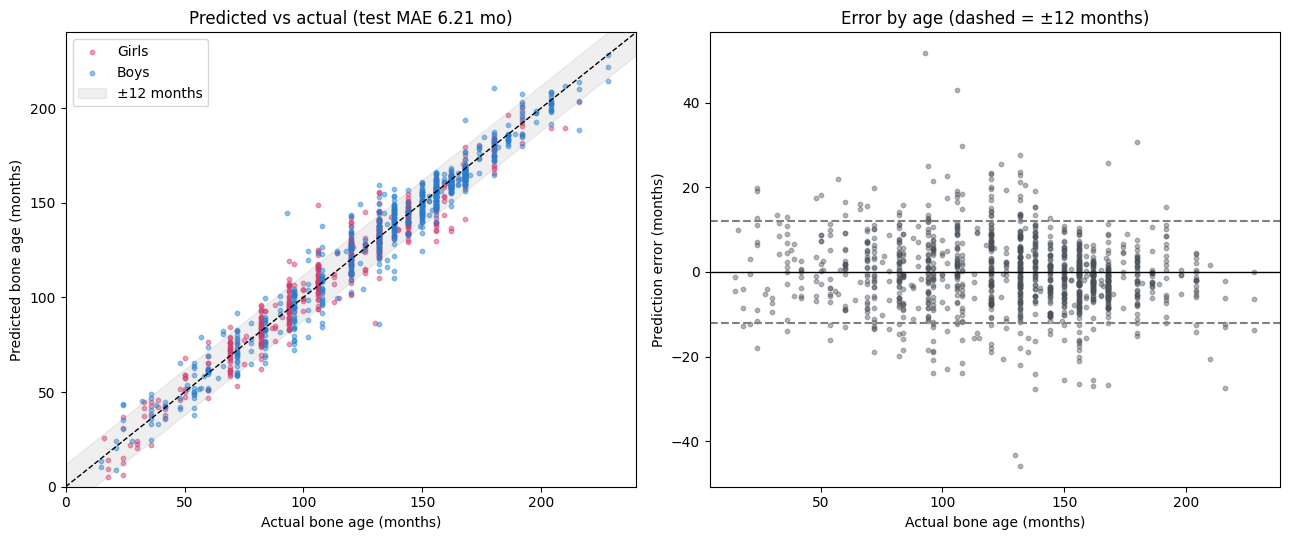

In [27]:
import matplotlib.pyplot as plt
male = test_df.reset_index(drop=True)["male"].values
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for sex, name, c in [(0, "Girls", "#d6336c"), (1, "Boys", "#1c7ed6")]:
    m = male == sex
    ax[0].scatter(y[m], p[m], s=10, alpha=0.45, c=c, label=name)
ax[0].plot([0, 240], [0, 240], "k--", lw=1)
ax[0].fill_between([0, 240], [-12, 228], [12, 252], color="gray", alpha=0.12, label="±12 months")
ax[0].set(xlim=(0, 240), ylim=(0, 240), xlabel="Actual bone age (months)",
          ylabel="Predicted bone age (months)", title=f"Predicted vs actual (test MAE {err.mean():.2f} mo)")
ax[0].legend()
ax[1].scatter(y, p - y, s=10, alpha=0.4, c="#495057")
ax[1].axhline(0, c="k", lw=1); ax[1].axhline(12, c="gray", ls="--"); ax[1].axhline(-12, c="gray", ls="--")
ax[1].set(xlabel="Actual bone age (months)", ylabel="Prediction error (months)", title="Error by age (dashed = ±12 months)")
plt.tight_layout(); plt.savefig("pred_vs_actual.png", dpi=200); plt.show()

In [28]:
print("AGE_MEAN =", AGE_MEAN, "| AGE_STD =", AGE_STD)

AGE_MEAN = 127.32226407613005 | AGE_STD = 41.17428364568501
